# Mapping player and team profiles at Worlds 2024

**Patricio Flores Uribe · Individual data analysis project**

Do players with similar resource use, damage and vision form recognizable groups after accounting for their different roles? I used Mapper and persistent homology to examine 81 players from 16 teams at the 2024 League of Legends World Championship. I then compared team-level statistics and topological features against observed tournament performance.

## Reading the results

The global Mapper graph contained 36 nodes. Its largest connected component contained 33, indicating that most profiles were linked through overlapping clusters at the selected parameters. That is evidence of continuity in this representation. It does not establish a fixed set of playstyles.

For team mean win rate, leave-one-team-out linear regression produced an R² of 0.723 with role statistics, −2.206 with topological features alone and 0.816 when both were combined. With 16 teams and preprocessing fitted to the full sample, these scores describe the observed sample. The input reports player aggregates without match dates, so it cannot establish which measurements were available before a given match.

## Data and execution

The saved figures and results come from the original analysis. To rerun it, place `player_statistics_cleaned_final.csv` beside the notebook, launch Jupyter in that directory and run the cells in order. The SHA-256 checksum of the original input is `86b95f1b49bab9555f00618e165df4b0c56fabe31cb86f1f6462034ac3a04041`. The file has 81 player rows, 27 columns and five role labels (`Top`, `Jungle`, `Mid`, `Adc`, `Support`).

Kaggle lists a CSV of that name in **2024 LoL Championship Player Stats & Swiss Stage**, published by **anxuanng (@anmatngu)** under the MIT license. Its last update was October 26, 2024, before the final. The Kaggle file's checksum has not been independently compared with the checksum above. [Kaggle data card and download](https://www.kaggle.com/datasets/anmatngu/2024-lol-championship-player-stats-and-swiss-stage)

A public mirror has the same headers and player order. After allowing for numerical differences smaller than 10⁻¹², one value differs. The mirror gives crisp’s kill participation (`KP%`) as 0.750, compared with approximately 0.751 in the original input. If using this CSV, rename it to `player_statistics_cleaned_final.csv` and expect that some outputs may differ. [Alternate CSV](https://github.com/gaomengsuanjia/-LOL-S14-/blob/main/data/data.csv)

The core fields are `PlayerName`, `TeamName`, `Position`, `Games`, `Win rate`, `KDA`, `GoldPerMin`, `DPM`, `CSPerMin`, `KP%` and `VSPM`. The player regression uses additional columns listed in its code when available. Use the original CSV to reproduce that specification. The supplementary comparison adds the final tournament bracket as a separate outcome table.

The original kernel was Python 3.9.6. Dependencies are Jupyter/IPython, NumPy, pandas, Matplotlib, NetworkX, SciPy, scikit-learn, Ripser, Persim and KeplerMapper (Python package `kmapper`). The notebook writes figures to `figures/` and interactive Mapper graphs to `outputs/`.

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import networkx as nx

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.model_selection import KFold, GroupKFold, LeaveOneOut, cross_val_score
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, mean_absolute_error,
                             mean_squared_error, r2_score)
from scipy.stats import spearmanr

from ripser import ripser
import persim
from persim import PersistenceImager, bottleneck
import kmapper as km

os.makedirs('outputs', exist_ok=True)
os.makedirs('figures', exist_ok=True)
print('Imports listos.')


Imports listos.


In [2]:
PALETTE = {
    'bg': '#f6f7fb', 'grid': '#d5d9e6', 'ink': '#1f2430',
    'pri': '#3859ff', 'sec': '#ff6f59', 'ok': '#1ec07d', 'warn': '#f5a524',
    'roles': {'Top':'#3859ff','Jungle':'#1ec07d','Mid':'#ff6f59',
              'Adc':'#f5a524','Support':'#9b59b6'}
}
mpl.rcParams.update({
    'figure.facecolor': PALETTE['bg'],
    'axes.facecolor': PALETTE['bg'],
    'axes.edgecolor': PALETTE['ink'],
    'axes.labelcolor': PALETTE['ink'],
    'axes.titlecolor': PALETTE['ink'],
    'axes.grid': True,
    'grid.color': PALETTE['grid'],
    'grid.alpha': 0.6,
    'xtick.color': PALETTE['ink'],
    'ytick.color': PALETTE['ink'],
    'font.family': 'DejaVu Sans',
    'font.size': 10,
})
np.random.seed(7)


## Inspect player-level input

Check dimensions, missing values and duplicate records. The table records player aggregates without game identifiers, timestamps or elimination labels. The individual matches contributing to each row cannot be recovered from these data.

In [3]:
df = pd.read_csv('player_statistics_cleaned_final.csv')
print('Shape:', df.shape)
print('Posiciones:', df['Position'].value_counts().to_dict())
print('Equipos unicos:', df['TeamName'].nunique())

FEATURES = ['KDA', 'GoldPerMin', 'DPM', 'CSPerMin', 'KP%', 'VSPM']
print('\nMetricas core:')
print(FEATURES)

print('\nNulos por columna core:', df[FEATURES].isna().sum().sum())
print('Filas duplicadas:', df.duplicated().sum())


In [4]:
TIME_COLS = [c for c in df.columns if any(k in c.lower() for k in
              ['date','time','match','phase','round','stage','game_id'])]
ELIM_COLS = [c for c in df.columns if any(k in c.lower() for k in
              ['elim','knock','advance','final_pos','bracket','result_match'])]
print('Columnas temporales detectadas:', TIME_COLS or 'NINGUNA')
print('Columnas de eliminacion detectadas:', ELIM_COLS or 'NINGUNA')

print('\nWin rate medio por equipo (top 8):')
print(df.groupby('TeamName')['Win rate'].mean().sort_values(ascending=False).head(8))
print('\n(bottom 8):')
print(df.groupby('TeamName')['Win rate'].mean().sort_values(ascending=False).tail(8))


Columnas temporales detectadas: NINGUNA
Columnas de eliminacion detectadas: NINGUNA

Win rate medio por equipo (top 8):
TeamName
T1                     0.875000
Gen.G                  0.700000
Bilibili Gaming        0.629833
LNG Esports            0.625000
Weibo Gaming           0.615000
FlyQuest               0.500000
Hanwha Life Esports    0.500000
Team Liquid            0.500000
Name: Win rate, dtype: float64

(bottom 8):
TeamName
Top Esports      0.500
G2 Esports       0.375
GAM Esports      0.375
Dplus KIA        0.333
Fnatic           0.333
MAD Lions KOI    0.200
PSG Talon        0.200
PaiN Gaming      0.000
Name: Win rate, dtype: float64


## Represent each player with six measurements

The six coordinates describe efficiency, resources, damage and vision. Keep player identities, team membership and positions available to interpret the plots separately from the numerical features.

In [5]:
META_COLS = [c for c in ['PlayerName', 'TeamName', 'Position', 'Country', 'FlashKeybind']
             if c in df.columns]
X_player_raw = df[FEATURES].values
print('X_player_raw.shape =', X_player_raw.shape)
print('Metadata conservada:', META_COLS)


X_player_raw.shape = (81, 6)
Metadata conservada: ['PlayerName', 'TeamName', 'Position', 'Country', 'FlashKeybind']


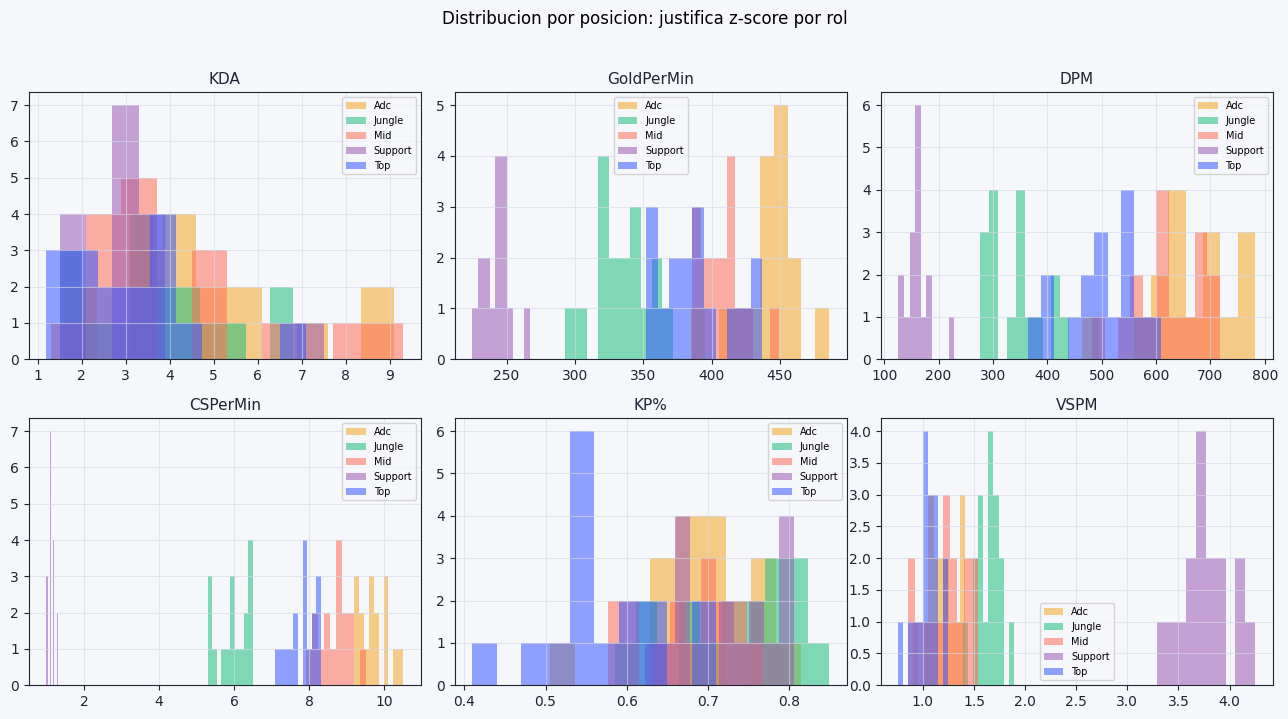

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, feat in zip(axes.flatten(), FEATURES):
    for pos in sorted(df['Position'].unique()):
        ax.hist(df.loc[df['Position']==pos, feat].values,
                bins=10, alpha=0.55, label=pos,
                color=PALETTE['roles'].get(pos, '#777'))
    ax.set_title(feat, fontsize=11)
    ax.legend(fontsize=7)
fig.suptitle('Distribucion por posicion: justifica z-score por rol', y=1.02)
fig.tight_layout()
fig.savefig('figures/01_distribuciones_por_posicion.png', dpi=120, bbox_inches='tight')
plt.show()


## Standardize within playing position

Gold, damage and vision have different typical levels for different roles. Standardizing each metric within position makes a support or jungler comparable to peers playing that role.

In [7]:
def zscore_within_position(frame, features):
    out = frame.copy()
    for pos, sub in out.groupby('Position'):
        for f in features:
            mu = sub[f].mean()
            sd = sub[f].std(ddof=0)
            if sd == 0:
                sd = 1.0
            out.loc[sub.index, f + '_z'] = (sub[f].values - mu) / sd
    return out

df_z = zscore_within_position(df, FEATURES)
Z_COLS = [f + '_z' for f in FEATURES]
X_player = df_z[Z_COLS].values

print('Media por posicion (deberia ser ~0):')
print(df_z.groupby('Position')[Z_COLS].mean().round(3))
print('\nStd por posicion (deberia ser ~1):')
print(df_z.groupby('Position')[Z_COLS].std(ddof=0).round(3))
print('\nX_player.shape =', X_player.shape)


Media por posicion (deberia ser ~0):
          KDA_z  GoldPerMin_z  DPM_z  CSPerMin_z  KP%_z  VSPM_z
Position                                                       
Adc         0.0          -0.0   -0.0         0.0   -0.0    -0.0
Jungle     -0.0           0.0   -0.0        -0.0   -0.0    -0.0
Mid        -0.0           0.0   -0.0        -0.0    0.0     0.0
Support     0.0           0.0   -0.0        -0.0   -0.0     0.0
Top        -0.0           0.0    0.0        -0.0   -0.0     0.0

Std por posicion (deberia ser ~1):
          KDA_z  GoldPerMin_z  DPM_z  CSPerMin_z  KP%_z  VSPM_z
Position                                                       
Adc         1.0           1.0    1.0         1.0    1.0     1.0
Jungle      1.0           1.0    1.0         1.0    1.0     1.0
Mid         1.0           1.0    1.0         1.0    1.0     1.0
Support     1.0           1.0    1.0         1.0    1.0     1.0
Top         1.0           1.0    1.0         1.0    1.0     1.0

X_player.shape = (81, 6)


## Build a role-preserving team profile

For each team, concatenate one six-dimensional profile for each of the five roles in a fixed order. If the roster has two players in the same role, use the player who played the most games. This produces a 30-coordinate team vector.

In [8]:
POS_ORDER = ['Top', 'Jungle', 'Mid', 'Adc', 'Support']

def starter_row(team_df, pos):
    sub = team_df[team_df['Position'] == pos]
    if len(sub) == 0:
        return None
    return sub.sort_values('Games', ascending=False).iloc[0]

def team_vector(team_df, pos_order=POS_ORDER, zcols=Z_COLS):
    parts = []
    for pos in pos_order:
        r = starter_row(team_df, pos)
        if r is None:
            return None
        parts.extend([r[c] for c in zcols])
    return np.array(parts)

team_names, X_team_rows, starter_indices = [], [], []
for team, team_df in df_z.groupby('TeamName'):
    v = team_vector(team_df)
    if v is None:
        continue
    team_names.append(team)
    X_team_rows.append(v)
    for pos in POS_ORDER:
        r = starter_row(team_df, pos)
        starter_indices.append(r.name)

team_names = list(team_names)
X_team = np.vstack(X_team_rows)
print('X_team.shape =', X_team.shape, '   (equipos × 30)')
print('Total titulares seleccionados:', len(starter_indices),
      '(esperado:', len(team_names) * 5, ')')


X_team.shape = (16, 30)    (equipos × 30)
Total titulares seleccionados: 80 (esperado: 80 )


In [9]:
team_meta = pd.DataFrame({'TeamName': team_names})
team_meta['MeanWinRate'] = [df.loc[df['TeamName']==t, 'Win rate'].mean()
                            for t in team_names]
team_meta = team_meta.sort_values('MeanWinRate', ascending=False).reset_index(drop=True)
print(team_meta.to_string(index=False))


           TeamName  MeanWinRate
                 T1     0.875000
              Gen.G     0.700000
    Bilibili Gaming     0.629833
        LNG Esports     0.625000
       Weibo Gaming     0.615000
           FlyQuest     0.500000
Hanwha Life Esports     0.500000
        Team Liquid     0.500000
        Top Esports     0.500000
         G2 Esports     0.375000
        GAM Esports     0.375000
          Dplus KIA     0.333000
             Fnatic     0.333000
      MAD Lions KOI     0.200000
          PSG Talon     0.200000
        PaiN Gaming     0.000000


## Inspect the player cloud with principal components

Use a two-dimensional projection to compare how positions, team identities and observed win rates vary over the cloud.

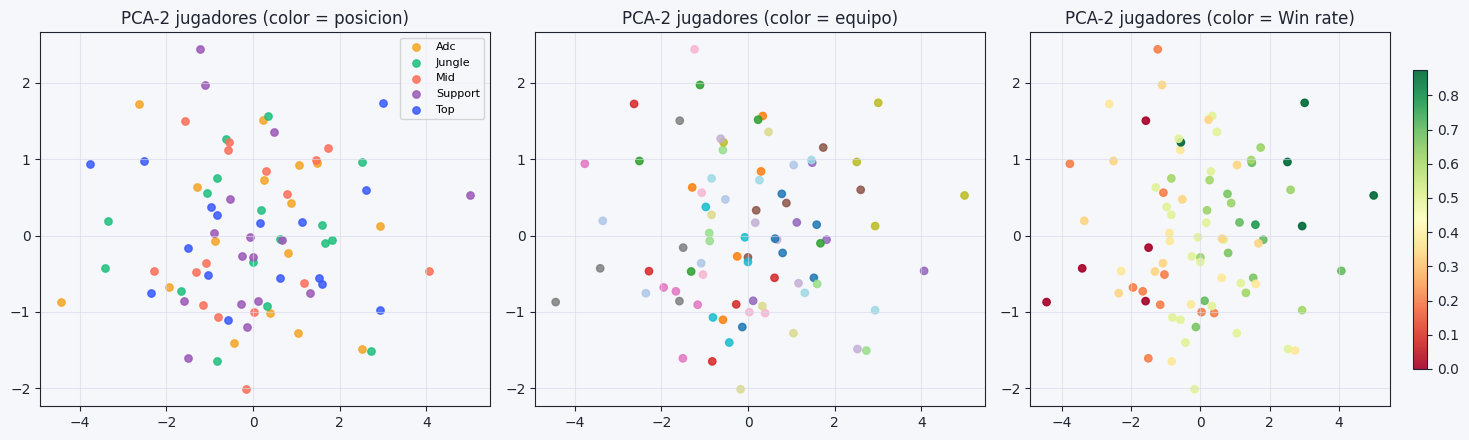

In [10]:
X_pca2 = PCA(n_components=2, random_state=7).fit_transform(X_player)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for pos in sorted(df_z['Position'].unique()):
    m = df_z['Position'] == pos
    axes[0].scatter(X_pca2[m, 0], X_pca2[m, 1], s=28, alpha=0.85,
                    label=pos, color=PALETTE['roles'].get(pos, '#777'))
axes[0].set_title('PCA-2 jugadores (color = posicion)')
axes[0].legend(fontsize=8)

team_codes = pd.Categorical(df_z['TeamName']).codes
sc = axes[1].scatter(X_pca2[:, 0], X_pca2[:, 1], c=team_codes, cmap='tab20',
                     s=28, alpha=0.85)
axes[1].set_title('PCA-2 jugadores (color = equipo)')

sc = axes[2].scatter(X_pca2[:, 0], X_pca2[:, 1], c=df['Win rate'].values,
                     cmap='RdYlGn', s=28, alpha=0.9)
axes[2].set_title('PCA-2 jugadores (color = Win rate)')
fig.colorbar(sc, ax=axes[2], shrink=0.8)
fig.tight_layout()
fig.savefig('figures/02_pca_jugadores.png', dpi=120, bbox_inches='tight')
plt.show()


## Identify connected components and loops

Compute Vietoris–Rips persistence for the full player cloud, each role and the role-preserving team vectors. H₀ records when disconnected groups merge as the distance scale increases. H₁ records loops that appear and disappear. These are geometric features in an aggregate dataset.

Resumen topologico global:
                            nube: jugadores R^6
                      H0_finitos: 80
                    H0_infinitos: 1
                        H1_loops: 43
                     H1_pers_max: 0.4146232604980469
                   H1_pers_total: 6.29632306098938
          H1_prop_lejos_diagonal: 0.7209302325581395


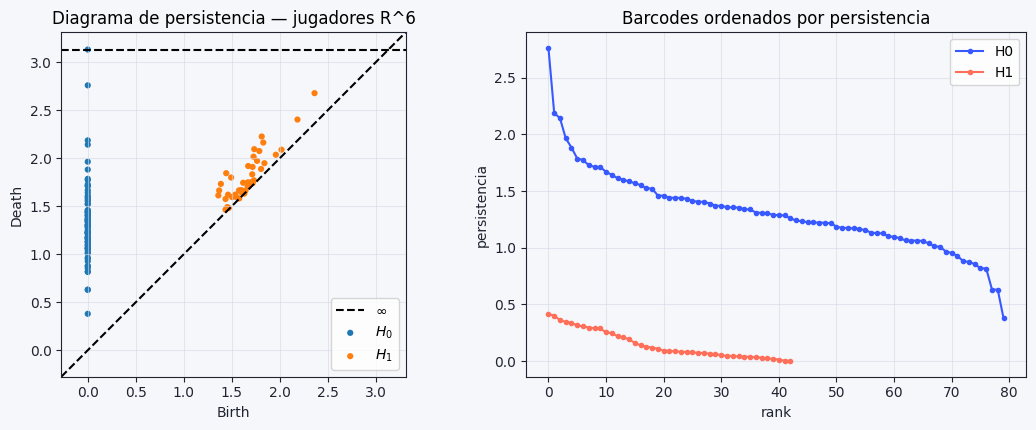

In [11]:
def persistence_summary(dgms, label='?'):
    h0 = dgms[0]
    h1 = dgms[1] if len(dgms) > 1 else np.empty((0, 2))
    h0_finite = h0[np.isfinite(h0[:, 1])]
    h1_finite = h1[np.isfinite(h1[:, 1])]
    diag = (h1_finite[:, 1] - h1_finite[:, 0]) if len(h1_finite) else np.array([])
    summary = {
        'nube': label,
        'H0_finitos': len(h0_finite),
        'H0_infinitos': int(np.sum(~np.isfinite(h0[:, 1]))),
        'H1_loops': len(h1_finite),
        'H1_pers_max': float(diag.max()) if len(diag) else 0.0,
        'H1_pers_total': float(diag.sum()) if len(diag) else 0.0,
        'H1_prop_lejos_diagonal': float(np.mean(diag > 0.05)) if len(diag) else 0.0,
    }
    return summary

dgms_global = ripser(X_player, maxdim=1)['dgms']
summary_global = persistence_summary(dgms_global, 'jugadores R^6')
print('Resumen topologico global:')
for k, v in summary_global.items():
    print(f'  {k:>30}: {v}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
persim.plot_diagrams(dgms_global, ax=axes[0], show=False)
axes[0].set_title('Diagrama de persistencia — jugadores R^6')
for dim, (color, name) in enumerate([(PALETTE['pri'], 'H0'), (PALETTE['sec'], 'H1')]):
    if dim < len(dgms_global):
        d = dgms_global[dim]
        d = d[np.isfinite(d[:, 1])]
        if len(d):
            persistences = sorted(d[:, 1] - d[:, 0], reverse=True)
            axes[1].plot(persistences, '-o', color=color, label=name, markersize=3)
axes[1].set_xlabel('rank')
axes[1].set_ylabel('persistencia')
axes[1].set_title('Barcodes ordenados por persistencia')
axes[1].legend()
fig.tight_layout()
fig.savefig('figures/03_vr_global.png', dpi=120, bbox_inches='tight')
plt.show()


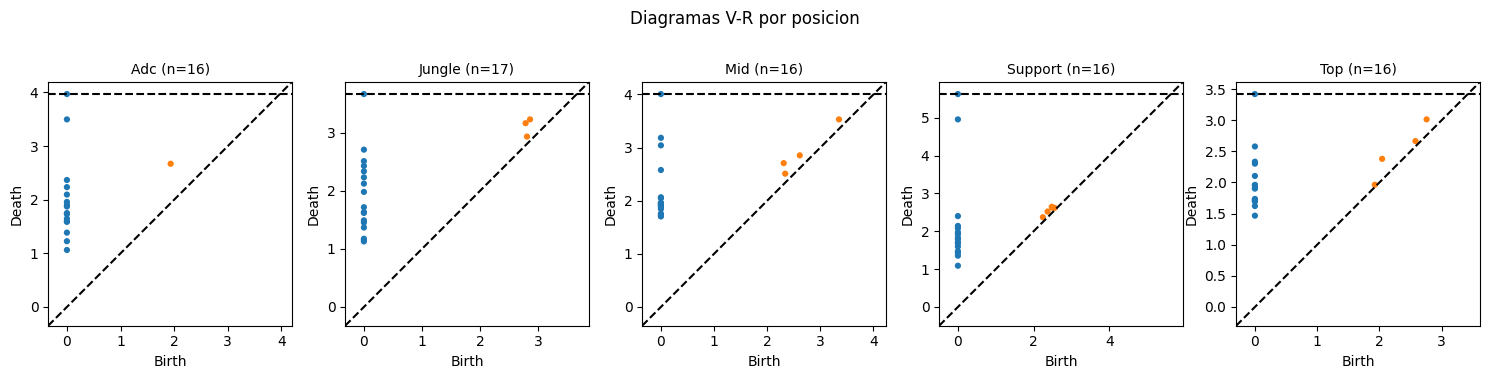

      nube  H0_finitos  H0_infinitos  H1_loops  H1_pers_max  H1_pers_total  \
0      Adc          15             1         1        0.736          0.736   
1   Jungle          16             1         3        0.380          0.875   
2      Mid          15             1         4        0.396          0.984   
3  Support          15             1         5        0.166          0.635   
4      Top          15             1         4        0.335          0.714   

   H1_prop_lejos_diagonal  
0                    1.00  
1                    1.00  
2                    1.00  
3                    1.00  
4                    0.75  

In [12]:
POS_LIST = sorted(df_z['Position'].unique())
fig, axes = plt.subplots(1, len(POS_LIST), figsize=(3.0*len(POS_LIST), 3.4))
rows = []
for ax, pos in zip(axes, POS_LIST):
    Xp = df_z[df_z['Position']==pos][Z_COLS].values
    dg = ripser(Xp, maxdim=1)['dgms']
    persim.plot_diagrams(dg, ax=ax, show=False, legend=False)
    ax.set_title(f'{pos} (n={len(Xp)})', fontsize=10)
    s = persistence_summary(dg, pos)
    rows.append(s)
fig.suptitle('Diagramas V-R por posicion', y=1.04)
fig.tight_layout()
fig.savefig('figures/04_vr_por_posicion.png', dpi=120, bbox_inches='tight')
plt.show()

pd.DataFrame(rows).round(3)


{'nube': 'equipos R^30', 'H0_finitos': 15, 'H0_infinitos': 1, 'H1_loops': 2, 'H1_pers_max': 0.4256172180175781, 'H1_pers_total': 0.5971331596374512, 'H1_prop_lejos_diagonal': 1.0}


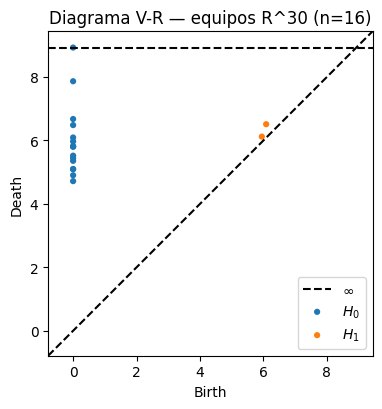

In [13]:
dgms_team = ripser(X_team, maxdim=1)['dgms']
summary_team = persistence_summary(dgms_team, 'equipos R^30')
print(summary_team)

fig, ax = plt.subplots(figsize=(5.5, 4.2))
persim.plot_diagrams(dgms_team, ax=ax, show=False)
ax.set_title('Diagrama V-R — equipos R^30 (n=16)')
fig.tight_layout()
fig.savefig('figures/05_vr_equipos.png', dpi=120, bbox_inches='tight')
plt.show()


## Build the global Mapper graph

Use the first principal component as the lens. Sweep the number of overlapping intervals, the overlap fraction and the clustering method. Each node represents a cluster within an interval. An edge means that two nodes share at least one player. The selection rule below favors viable graphs with cycles and a large connected component; graph size and cycle counts depend on this choice.

In [14]:
def mapper_to_networkx(graph_dict):
    G = nx.Graph()
    nodes_dict = graph_dict.get('nodes', {})
    for node_id, members in nodes_dict.items():
        G.add_node(node_id, members=list(members))
    for n1, neigh in graph_dict.get('links', {}).items():
        for n2 in neigh:
            G.add_edge(n1, n2)
    return G

def graph_stats(G):
    if G.number_of_nodes() == 0:
        return dict(nodes=0, edges=0, components=0, largest_cc=0,
                    cycles=0, avg_degree=0.0)
    comps = list(nx.connected_components(G))
    largest = max((len(c) for c in comps), default=0)
    cycles = G.number_of_edges() - G.number_of_nodes() + len(comps)
    avg_deg = (2*G.number_of_edges()/G.number_of_nodes())
    return dict(nodes=G.number_of_nodes(), edges=G.number_of_edges(),
                components=len(comps), largest_cc=largest,
                cycles=cycles, avg_degree=round(avg_deg, 3))

def build_mapper(X, lens, n_cubes, overlap, clusterer):
    mapper = km.KeplerMapper(verbose=0)
    graph = mapper.map(lens, X,
                       cover=km.Cover(n_cubes=n_cubes, perc_overlap=overlap),
                       clusterer=clusterer)
    G = mapper_to_networkx(graph)
    return mapper, graph, G


In [15]:
lens_player = PCA(n_components=1, random_state=7).fit_transform(X_player)

sweep_rows = []
for nc in [6, 10, 14]:
    for ov in [0.2, 0.4, 0.6]:
        for clab, cl in [
                ('DBSCAN_eps0.8', DBSCAN(eps=0.8, min_samples=2)),
                ('DBSCAN_eps1.2', DBSCAN(eps=1.2, min_samples=2)),
                ('KMeans_k3',     KMeans(n_clusters=3, n_init=10, random_state=7))]:
            try:
                _, _, G = build_mapper(X_player, lens_player, nc, ov, cl)
                s = graph_stats(G)
                s.update({'n_cubes': nc, 'overlap': ov, 'clusterer': clab})
                sweep_rows.append(s)
            except Exception:
                continue
sweep_df = pd.DataFrame(sweep_rows)
sweep_df['frag'] = (sweep_df['components'] / sweep_df['nodes']).round(3)
sweep_df['rel_largest'] = (sweep_df['largest_cc'] / sweep_df['nodes']).round(3)

viable = sweep_df[(sweep_df['nodes'] >= 18) & (sweep_df['frag'] < 0.7)
                  & (sweep_df['rel_largest'] >= 0.30)]
viable = viable.sort_values(['cycles', 'rel_largest'], ascending=[False, False])
print('Top configuraciones viables:')
print(viable.head(5).to_string(index=False))


Top configuraciones viables:
 nodes  edges  components  largest_cc  cycles  avg_degree  n_cubes  overlap clusterer  frag  rel_largest
    36     70           3          33      37       3.889       14      0.6 KMeans_k3 0.083        0.917
    27     58           2          26      33       4.296       10      0.6 KMeans_k3 0.074        0.963
    18     35           2          17      19       3.889        6      0.6 KMeans_k3 0.111        0.944
    27     30           5          20       8       2.222       10      0.4 KMeans_k3 0.185        0.741
    33     34           7          24       8       2.061       14      0.4 KMeans_k3 0.212        0.727


In [16]:
best = viable.iloc[0]
NCUBES = int(best['n_cubes'])
OVL = float(best['overlap'])
CLNAME = best['clusterer']
clusterer = (DBSCAN(eps=0.8, min_samples=2) if CLNAME == 'DBSCAN_eps0.8'
             else DBSCAN(eps=1.2, min_samples=2) if CLNAME == 'DBSCAN_eps1.2'
             else KMeans(n_clusters=3, n_init=10, random_state=7))
mapper_pl, graph_pl, G_pl = build_mapper(X_player, lens_player, NCUBES, OVL, clusterer)
print(f'Eleccion final: n_cubes={NCUBES}, overlap={OVL}, clusterer={CLNAME}')
print('Mapper jugadores final:', graph_stats(G_pl))


Eleccion final: n_cubes=14, overlap=0.6, clusterer=KMeans_k3
Mapper jugadores final: {'nodes': 36, 'edges': 70, 'components': 3, 'largest_cc': 33, 'cycles': 37, 'avg_degree': 3.889}


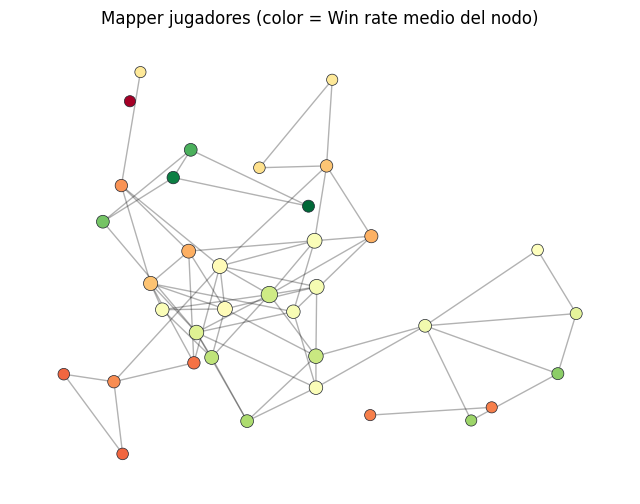

HTML: True 85138 bytes

Top 5 nodos por Win rate medio (descriptivo):
           nodo  n pos_dom  wr_medio
cube11_cluster1  3     Adc  0.875000
cube10_cluster1  4  Jungle  0.831250
 cube9_cluster2  5  Jungle  0.729000
 cube8_cluster0  5  Jungle  0.679000
cube11_cluster2  3     Top  0.646667

Bottom 5:
          nodo  n pos_dom  wr_medio
cube0_cluster1  1     Adc   0.00000
cube0_cluster0  2  Jungle   0.16650
cube1_cluster0  2  Jungle   0.16650
cube3_cluster0  4 Support   0.18325
cube0_cluster2  1     Top   0.20000


In [17]:
def draw_mapper(G, color_by, cmap='RdYlGn', title='', path=None, ax=None):
    pos = nx.spring_layout(G, seed=7, k=0.6)
    if ax is None:
        fig, ax = plt.subplots(figsize=(7.5, 5.5))
    sizes = [60 + 5*len(G.nodes[n].get('members', [])) for n in G.nodes]
    colors = [color_by.get(n, 0.5) for n in G.nodes]
    nx.draw_networkx_edges(G, pos, alpha=0.3, ax=ax)
    nx.draw_networkx_nodes(G, pos, node_size=sizes, node_color=colors,
                           cmap=cmap, edgecolors=PALETTE['ink'], linewidths=0.5,
                           ax=ax)
    ax.set_axis_off()
    ax.set_title(title)
    if path is not None:
        plt.savefig(path, dpi=120, bbox_inches='tight')
    return ax

wr_arr = df['Win rate'].values
node_wr = {n: float(np.mean(wr_arr[list(G_pl.nodes[n]['members'])]))
           for n in G_pl.nodes}
fig, ax = plt.subplots(figsize=(8, 6))
draw_mapper(G_pl, node_wr, cmap='RdYlGn',
            title='Mapper jugadores (color = Win rate medio del nodo)',
            path='figures/06_mapper_jugadores.png', ax=ax)
plt.show()

mapper_pl.visualize(graph_pl,
                    path_html='outputs/mapper_players_global.html',
                    title='Mapper jugadores global (color = Win rate)',
                    color_values=wr_arr,
                    color_function_name='Win rate',
                    custom_tooltips=df['PlayerName'].values)
print('HTML:', os.path.exists('outputs/mapper_players_global.html'),
      os.path.getsize('outputs/mapper_players_global.html'), 'bytes')

node_rows = []
for n in G_pl.nodes:
    members = list(G_pl.nodes[n]['members'])
    sub = df.iloc[members]
    pos_dom = sub['Position'].mode().iloc[0] if len(sub) else None
    node_rows.append({
        'nodo': n, 'n': len(members), 'pos_dom': pos_dom,
        'wr_medio': float(sub['Win rate'].mean()),
    })
nodes_df = pd.DataFrame(node_rows)
print('\nTop 5 nodos por Win rate medio (descriptivo):')
print(nodes_df.sort_values('wr_medio', ascending=False).head(5).to_string(index=False))
print('\nBottom 5:')
print(nodes_df.sort_values('wr_medio').head(5).to_string(index=False))


## Recolor the global graph by role

Use the same nodes and edges, labeling nodes by their dominant playing position. Compare the resulting pattern with the win-rate coloring.

In [18]:
pos_codes = pd.Categorical(df_z['Position']).codes.astype(float)
mapper_pl.visualize(graph_pl,
                    path_html='outputs/mapper_players_by_position.html',
                    title='Mapper jugadores (color = posicion)',
                    color_values=pos_codes,
                    color_function_name='Position code',
                    custom_tooltips=(df['PlayerName'] + ' (' + df['Position'] + ')').values)
print('HTML:', os.path.exists('outputs/mapper_players_by_position.html'),
      os.path.getsize('outputs/mapper_players_by_position.html'), 'bytes')


HTML: True 86335 bytes


## Map team profiles

Apply Mapper to the 16 role-preserving team vectors. Color local groups by their average observed win rate. The small sample limits how much weight to put on individual clusters.

Mapper equipos: {'nodes': 15, 'edges': 9, 'components': 6, 'largest_cc': 6, 'cycles': 0, 'avg_degree': 1.2}
HTML: True 62550 bytes


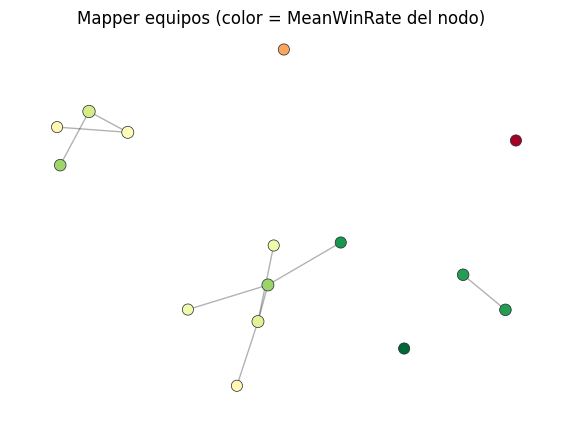

In [19]:
# alinear team_meta al orden de team_names
tm_idx = {t: i for i, t in enumerate(team_names)}
mwr_team = np.array([team_meta.set_index('TeamName').loc[t, 'MeanWinRate']
                     for t in team_names])

lens_team_pca = PCA(n_components=1, random_state=7).fit_transform(X_team)
mapper_t, graph_t, G_t = build_mapper(X_team, lens_team_pca,
                                      n_cubes=6, overlap=0.5,
                                      clusterer=KMeans(n_clusters=3, n_init=10,
                                                       random_state=7))
print('Mapper equipos:', graph_stats(G_t))

mapper_t.visualize(graph_t,
                   path_html='outputs/mapper_teams_roles.html',
                   title='Mapper equipos R^30 (color = MeanWinRate)',
                   color_values=mwr_team,
                   color_function_name='MeanWinRate',
                   custom_tooltips=np.array(team_names))
print('HTML:', os.path.exists('outputs/mapper_teams_roles.html'),
      os.path.getsize('outputs/mapper_teams_roles.html'), 'bytes')

node_color = {n: float(np.mean([mwr_team[m] for m in G_t.nodes[n]['members']]))
              for n in G_t.nodes}
fig, ax = plt.subplots(figsize=(7, 5))
draw_mapper(G_t, node_color, cmap='RdYlGn',
            title='Mapper equipos (color = MeanWinRate del nodo)',
            path='figures/07_mapper_equipos.png', ax=ax)
plt.show()


## Look specifically at resources, damage and vision

Build a second player graph using a two-coordinate lens. The first coordinate is standardized gold per minute. The second adds standardized damage and vision per minute. Compare the connections under this lens with those in the global graph.

Mapper recursos-dano-vision: {'nodes': 105, 'edges': 268, 'components': 5, 'largest_cc': 94, 'cycles': 168, 'avg_degree': 5.105}


HTML: True 157173 bytes


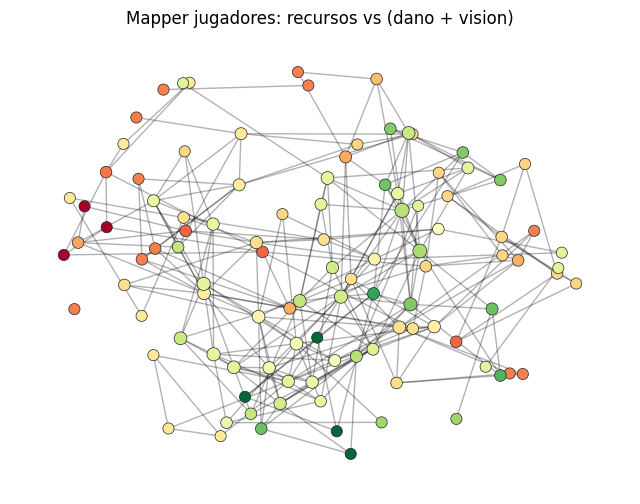

In [20]:
lens_rdv = np.column_stack([
    df_z['GoldPerMin_z'].values,
    df_z['DPM_z'].values + df_z['VSPM_z'].values,
])
mapper_rdv, graph_rdv, G_rdv = build_mapper(
    X_player, lens_rdv, n_cubes=10, overlap=0.5,
    clusterer=KMeans(n_clusters=3, n_init=10, random_state=7))
print('Mapper recursos-dano-vision:', graph_stats(G_rdv))

mapper_rdv.visualize(
    graph_rdv,
    path_html='outputs/mapper_players_resource_damage_vision.html',
    title='Mapper jugadores: lens (GPM_z, DPM_z+VSPM_z)',
    color_values=wr_arr,
    color_function_name='Win rate',
    custom_tooltips=(df['PlayerName'] + ' (' + df['Position'] + ')').values,
)
print('HTML:', os.path.exists('outputs/mapper_players_resource_damage_vision.html'),
      os.path.getsize('outputs/mapper_players_resource_damage_vision.html'), 'bytes')

node_color = {n: float(np.mean(wr_arr[list(G_rdv.nodes[n]['members'])]))
              for n in G_rdv.nodes}
fig, ax = plt.subplots(figsize=(8, 6))
draw_mapper(G_rdv, node_color, cmap='RdYlGn',
            title='Mapper jugadores: recursos vs (dano + vision)',
            path='figures/08_mapper_recursos_dano_vision.png', ax=ax)
plt.show()


## Turn each roster’s persistence diagrams into features

For each roster, compute persistence on its players. Vectorize the finite H₀ and H₁ intervals using persistence images and Betti curves. Compare that feature set with the 30-coordinate statistical profile and with their concatenation.

In [21]:
def finite_h0_h1(dgms):
    out = []
    for dim in (0, 1):
        if dim < len(dgms) and len(dgms[dim]):
            d = dgms[dim]
            d = d[np.isfinite(d[:, 1])]
            out.append(d)
        else:
            out.append(np.empty((0, 2)))
    return out

team_dgms_full = []
for t in team_names:
    members = df_z[df_z['TeamName'] == t]
    Xp = members[Z_COLS].values
    if len(Xp) < 2:
        team_dgms_full.append([np.empty((0,2)), np.empty((0,2))])
        continue
    dgms = ripser(Xp, maxdim=1)['dgms']
    team_dgms_full.append(dgms)

# Persistence Image (H0+H1 concatenated)
diagrams_concat = []
for d in team_dgms_full:
    fh = finite_h0_h1(d)
    if len(fh[0]) + len(fh[1]) > 0:
        concat = np.vstack([fh[0], fh[1]]) if len(fh[0]) and len(fh[1]) \
                 else (fh[0] if len(fh[0]) else fh[1])
    else:
        concat = np.array([[0.0, 0.05]])
    diagrams_concat.append(concat)

pim = PersistenceImager(pixel_size=0.05)
pim.fit(diagrams_concat)
PI_team = np.vstack([pim.transform(d).flatten() for d in diagrams_concat])

# Betti curve manual (H0+H1) sobre rejilla comun
all_births = np.concatenate([d[:, 0] for d in diagrams_concat])
all_deaths = np.concatenate([d[:, 1] for d in diagrams_concat])
grid = np.linspace(0, max(all_deaths.max(), 1e-3), 30)

def betti_dim(dgm_dim, grid):
    if len(dgm_dim) == 0:
        return np.zeros_like(grid)
    return np.array([np.sum((dgm_dim[:, 0] <= t) & (dgm_dim[:, 1] > t))
                     for t in grid], dtype=float)

Betti_team = []
for d in team_dgms_full:
    fh = finite_h0_h1(d)
    b0 = betti_dim(fh[0], grid)
    b1 = betti_dim(fh[1], grid)
    Betti_team.append(np.concatenate([b0, b1]))
Betti_team = np.vstack(Betti_team)

X_topo = np.hstack([PI_team, Betti_team])
X_hybrid = np.hstack([X_team, X_topo])

print('PersistenceImage:', PI_team.shape)
print('BettiCurve:', Betti_team.shape)
print('X_topo:', X_topo.shape, '  X_hybrid:', X_hybrid.shape)


PersistenceImage: (16, 4880)
BettiCurve: (16, 60)
X_topo: (16, 4940)   X_hybrid: (16, 4970)


## Estimate observed win rate and compare representations

At player level, compare fitted models with dummy baselines. The player regression uses shuffled folds; the classification groups by team. At team level, leave one team out at a time. The target is an observed aggregate. Standardization and diagram vectorization were fitted using the full sample, so these scores are descriptive benchmarks for this tournament.

In [22]:
# A) Regresion Win rate a nivel jugador
PRED_FEATS = ['KDA','GoldPerMin','DPM','CSPerMin','KP%','VSPM',
              'DamagePercent','Avg WPM','Avg WCPM','Avg VWPM',
              'GD@15','XPD@15']
PRED_FEATS = [c for c in PRED_FEATS if c in df.columns]
X_pred_pl = df[PRED_FEATS].values
y_wr_pl = df['Win rate'].values
print('Features de regresion (sin Win rate ni Games):', PRED_FEATS)
print('X_pred_pl:', X_pred_pl.shape)

kf = KFold(n_splits=5, shuffle=True, random_state=7)
def kf_eval(model, X, y):
    preds = np.zeros_like(y, dtype=float)
    for tr, te in kf.split(X):
        m = model.__class__(**model.get_params())
        m.fit(X[tr], y[tr])
        preds[te] = m.predict(X[te])
    return preds

models_reg = {
    'Dummy (mean)':    DummyRegressor(strategy='mean'),
    'LinearRegression': LinearRegression(),
    'Ridge (a=1.0)':   Ridge(alpha=1.0, random_state=7),
    'RandomForest 300': RandomForestRegressor(n_estimators=300, random_state=7),
}
rows = []
for name, m in models_reg.items():
    p = kf_eval(m, X_pred_pl, y_wr_pl)
    rows.append({'modelo': name,
                 'MAE': mean_absolute_error(y_wr_pl, p),
                 'RMSE': np.sqrt(mean_squared_error(y_wr_pl, p)),
                 'R2': r2_score(y_wr_pl, p)})
print('\nRegresion Win rate (jugador, KFold=5):')
print(pd.DataFrame(rows).round(3).to_string(index=False))


Features de regresion (sin Win rate ni Games): ['KDA', 'GoldPerMin', 'DPM', 'CSPerMin', 'KP%', 'VSPM', 'DamagePercent', 'Avg WPM', 'Avg WCPM', 'Avg VWPM', 'GD@15', 'XPD@15']
X_pred_pl: (81, 12)



Regresion Win rate (jugador, KFold=5):
          modelo   MAE  RMSE     R2
    Dummy (mean) 0.174 0.215 -0.013
LinearRegression 0.100 0.128  0.643
   Ridge (a=1.0) 0.103 0.129  0.633
RandomForest 300 0.120 0.148  0.521


In [23]:
# B) Clasificacion alto/bajo desempeno a nivel jugador
threshold = np.median(y_wr_pl)
y_high = (y_wr_pl >= threshold).astype(int)
print(f'Mediana Win rate = {threshold:.3f}')
print('Clases jugador:', dict(zip(*np.unique(y_high, return_counts=True))))

groups = df['TeamName'].values
gkf = GroupKFold(n_splits=8)
def gkf_eval(model, X, y, groups):
    preds = np.zeros_like(y)
    for tr, te in gkf.split(X, y, groups=groups):
        m = model.__class__(**model.get_params())
        m.fit(X[tr], y[tr])
        preds[te] = m.predict(X[te])
    return preds

models_cls = {
    'Dummy (most_freq)': DummyClassifier(strategy='most_frequent'),
    'LogisticRegression': LogisticRegression(max_iter=2000),
    'RandomForest 300':   RandomForestClassifier(n_estimators=300, random_state=7),
}
rows_c = []
preds_pl = {}
for name, m in models_cls.items():
    p = gkf_eval(m, X_pred_pl, y_high, groups)
    preds_pl[name] = p
    rows_c.append({
        'modelo': name,
        'accuracy': accuracy_score(y_high, p),
        'balanced_accuracy': balanced_accuracy_score(y_high, p),
        'F1': f1_score(y_high, p, zero_division=0),
    })
print('\nClasificacion Win rate >= mediana (jugador, GroupKFold=8 por equipo):')
print(pd.DataFrame(rows_c).round(3).to_string(index=False))
print('\nMatriz de confusion (RandomForest 300):')
print(confusion_matrix(y_high, preds_pl['RandomForest 300']))


Mediana Win rate = 0.500
Clases jugador: {0: 36, 1: 45}



Clasificacion Win rate >= mediana (jugador, GroupKFold=8 por equipo):
            modelo  accuracy  balanced_accuracy    F1
 Dummy (most_freq)     0.185              0.167 0.312
LogisticRegression     0.741              0.739 0.764
  RandomForest 300     0.704              0.694 0.745

Matriz de confusion (RandomForest 300):
[[22 14]
 [10 35]]


In [24]:
# C) Comparacion baseline vs topologico vs hibrido a nivel equipo (n=16, exploratorio)
y_team_wr = mwr_team

loo = LeaveOneOut()
def loo_reg_eval(X, y, label):
    rows = []
    for name, mdl in [
        ('Dummy (mean)', DummyRegressor(strategy='mean')),
        ('LinearRegression', LinearRegression()),
        ('Ridge (a=1.0)', Ridge(alpha=1.0, random_state=7)),
        ('RandomForest 300', RandomForestRegressor(n_estimators=300, random_state=7)),
    ]:
        preds = np.zeros_like(y)
        for tr, te in loo.split(X):
            m = mdl.__class__(**mdl.get_params())
            m.fit(X[tr], y[tr])
            preds[te] = m.predict(X[te])
        rows.append({'feature_set': label, 'modelo': name,
                     'MAE': mean_absolute_error(y, preds),
                     'RMSE': np.sqrt(mean_squared_error(y, preds)),
                     'R2': r2_score(y, preds)})
    return rows

all_rows = []
for X_, lab in [(X_team, 'Baseline R^30'),
                (X_topo, 'Topologico (PI+Betti)'),
                (X_hybrid, 'Hibrido R^30 + PI+Betti')]:
    all_rows += loo_reg_eval(X_, y_team_wr, lab)

print('Regresion MeanWinRate a nivel equipo (n=16, LOOCV, exploratorio):')
print(pd.DataFrame(all_rows).round(3).to_string(index=False))


Regresion MeanWinRate a nivel equipo (n=16, LOOCV, exploratorio):
            feature_set           modelo   MAE  RMSE     R2
          Baseline R^30     Dummy (mean) 0.181 0.225 -0.138
          Baseline R^30 LinearRegression 0.097 0.111  0.723
          Baseline R^30    Ridge (a=1.0) 0.091 0.106  0.749
          Baseline R^30 RandomForest 300 0.105 0.145  0.524
  Topologico (PI+Betti)     Dummy (mean) 0.181 0.225 -0.138
  Topologico (PI+Betti) LinearRegression 0.332 0.377 -2.206
  Topologico (PI+Betti)    Ridge (a=1.0) 0.234 0.289 -0.879
  Topologico (PI+Betti) RandomForest 300 0.186 0.245 -0.353
Hibrido R^30 + PI+Betti     Dummy (mean) 0.181 0.225 -0.138
Hibrido R^30 + PI+Betti LinearRegression 0.068 0.090  0.816
Hibrido R^30 + PI+Betti    Ridge (a=1.0) 0.077 0.101  0.770
Hibrido R^30 + PI+Betti RandomForest 300 0.139 0.189  0.195


In [25]:
# Clasificacion alto/bajo MeanWinRate a nivel equipo (n=16, LOOCV)
y_team_high = (y_team_wr >= np.median(y_team_wr)).astype(int)
print('Clases equipo (MeanWinRate >= mediana):',
      dict(zip(*np.unique(y_team_high, return_counts=True))))

def loo_cls_eval(X, y, label):
    rows = []
    for name, mdl in [
        ('Dummy (most_freq)', DummyClassifier(strategy='most_frequent')),
        ('LogReg', LogisticRegression(max_iter=2000)),
        ('RandomForest 300', RandomForestClassifier(n_estimators=300, random_state=7)),
    ]:
        preds = np.zeros_like(y)
        for tr, te in loo.split(X):
            m = mdl.__class__(**mdl.get_params())
            m.fit(X[tr], y[tr])
            preds[te] = m.predict(X[te])
        rows.append({'feature_set': label, 'modelo': name,
                     'accuracy': accuracy_score(y, preds),
                     'balanced_accuracy': balanced_accuracy_score(y, preds),
                     'F1': f1_score(y, preds, zero_division=0)})
    return rows

all_cls = []
for X_, lab in [(X_team, 'Baseline R^30'),
                (X_topo, 'Topologico (PI+Betti)'),
                (X_hybrid, 'Hibrido R^30 + PI+Betti')]:
    all_cls += loo_cls_eval(X_, y_team_high, lab)

print('\nClasificacion equipo MeanWinRate >= mediana (n=16, LOOCV, exploratorio):')
print(pd.DataFrame(all_cls).round(3).to_string(index=False))


Clases equipo (MeanWinRate >= mediana): {0: 7, 1: 9}



Clasificacion equipo MeanWinRate >= mediana (n=16, LOOCV, exploratorio):
            feature_set            modelo  accuracy  balanced_accuracy    F1
          Baseline R^30 Dummy (most_freq)     0.562              0.500 0.720
          Baseline R^30            LogReg     0.688              0.675 0.737
          Baseline R^30  RandomForest 300     0.750              0.730 0.800
  Topologico (PI+Betti) Dummy (most_freq)     0.562              0.500 0.720
  Topologico (PI+Betti)            LogReg     0.625              0.603 0.700
  Topologico (PI+Betti)  RandomForest 300     0.625              0.619 0.667
Hibrido R^30 + PI+Betti Dummy (most_freq)     0.562              0.500 0.720
Hibrido R^30 + PI+Betti            LogReg     0.875              0.857 0.900
Hibrido R^30 + PI+Betti  RandomForest 300     0.688              0.690 0.706


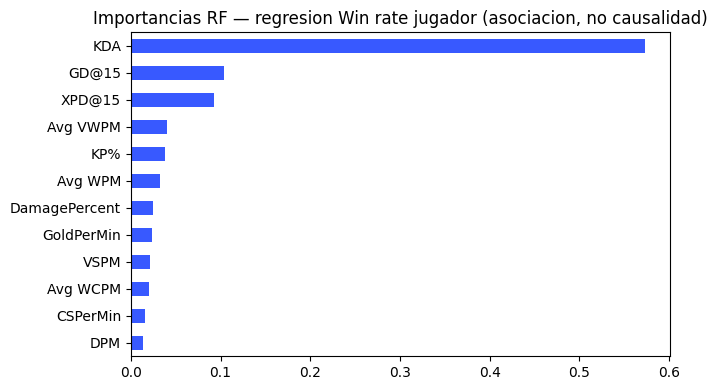

KDA              0.573
GD@15            0.104
XPD@15           0.092
Avg VWPM         0.040
KP%              0.038
Avg WPM          0.033
DamagePercent    0.024
GoldPerMin       0.024
VSPM             0.021
Avg WCPM         0.021
CSPerMin         0.016
DPM              0.014
dtype: float64


In [26]:
# Importancias relativas en RandomForest (regresion jugador)
rf = RandomForestRegressor(n_estimators=300, random_state=7).fit(X_pred_pl, y_wr_pl)
imp = pd.Series(rf.feature_importances_, index=PRED_FEATS).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
imp.plot.barh(ax=ax, color=PALETTE['pri'])
ax.invert_yaxis()
ax.set_title('Importancias RF — regresion Win rate jugador (asociacion, no causalidad)')
fig.tight_layout()
fig.savefig('figures/09_importancias_rf.png', dpi=120, bbox_inches='tight')
plt.show()
print(imp.round(3))


## Compare rosters at one point in time

Compare pairs of team H₁ diagrams with a bottleneck-distance diagnostic. The original plotting convention substitutes zero whenever either diagram has no finite H₁ intervals. Those entries are placeholders and cannot establish similarity. Game-by-game series would be needed to examine evolution through the tournament.

Pareja mas similar (cross-seccional H1): ('Bilibili Gaming', 'Dplus KIA', 0.0)
Pareja mas distinta:                   ('PaiN Gaming', 'Top Esports', 0.029878854751586914)


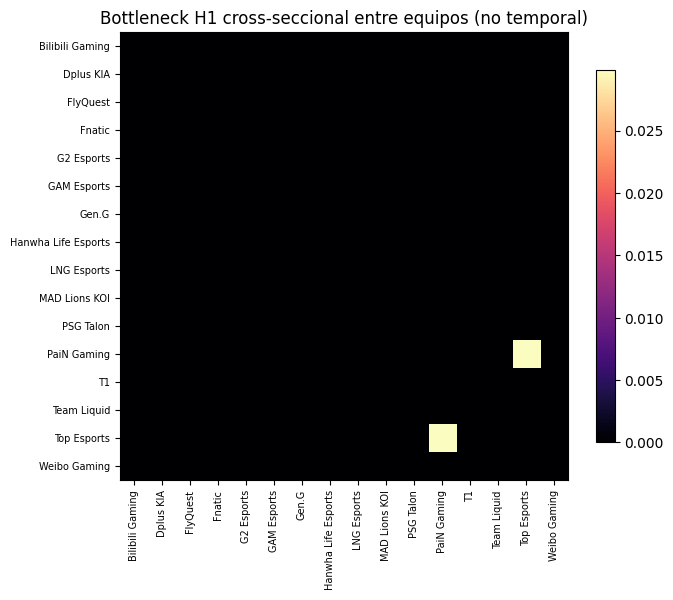

In [27]:
# Bottleneck cross-seccional (no temporal): exploratorio
def bottleneck_safe(d1, d2):
    fh1 = finite_h0_h1(d1)[1]
    fh2 = finite_h0_h1(d2)[1]
    if len(fh1) == 0 or len(fh2) == 0:
        return 0.0
    try:
        return float(bottleneck(fh1, fh2))
    except Exception:
        return np.nan

dist_bn = np.zeros((len(team_names), len(team_names)))
for i, t1 in enumerate(team_names):
    for j, t2 in enumerate(team_names):
        if i >= j:
            continue
        d = bottleneck_safe(team_dgms_full[i], team_dgms_full[j])
        dist_bn[i, j] = dist_bn[j, i] = d

iu = np.triu_indices(len(team_names), k=1)
flat = list(zip(np.array(team_names)[iu[0]], np.array(team_names)[iu[1]],
                dist_bn[iu]))
flat.sort(key=lambda x: x[2])
print('Pareja mas similar (cross-seccional H1):', flat[0])
print('Pareja mas distinta:                  ', flat[-1])

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(dist_bn, cmap='magma')
ax.set_xticks(range(len(team_names))); ax.set_xticklabels(team_names, rotation=90, fontsize=7)
ax.set_yticks(range(len(team_names))); ax.set_yticklabels(team_names, fontsize=7)
ax.set_title('Bottleneck H1 cross-seccional entre equipos (no temporal)')
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig('figures/10_bottleneck_equipos.png', dpi=120, bbox_inches='tight')
plt.show()


## What the topology adds

At the selected settings, 33 of 36 global Mapper nodes belonged to one connected component. This shows how overlapping player groups can connect across a role-adjusted spectrum. The 37 independent cycles in the Mapper graph and the 43 H₁ intervals in the player point cloud describe different constructions and should be interpreted separately.

The team comparison answers a more practical question: do geometric features add anything to ordinary role statistics? The linear model improved on this dataset when the two representations were combined. The topology-only linear model performed poorly, and combining them reduced the random forest’s R². The result depends on both representation and model choice.

## Retrospective check against tournament progression

Join Swiss and knockout results to the team features and ask how the classifications align with advancement. The final bracket supplies separate outcome labels. Without match dates in the input, this comparison cannot establish which features would have been available before qualification.

In [28]:
bracket_rows = [
    ('Gen.G',               '3-0', 1, 'Semifinalist',      4),
    ('LNG Esports',         '3-0', 1, 'Quarterfinalist',   3),
    ('T1',                  '3-1', 1, 'Champion',          6),
    ('Hanwha Life Esports', '3-1', 1, 'Quarterfinalist',   3),
    ('Top Esports',         '3-1', 1, 'Quarterfinalist',   3),
    ('Bilibili Gaming',     '3-2', 1, 'Runner-up',         5),
    ('Weibo Gaming',        '3-2', 1, 'Semifinalist',      4),
    ('FlyQuest',            '3-2', 1, 'Quarterfinalist',   3),
    ('Dplus KIA',           '2-3', 0, 'Eliminated Swiss 2-3', 2),
    ('G2 Esports',          '2-3', 0, 'Eliminated Swiss 2-3', 2),
    ('Team Liquid',         '2-3', 0, 'Eliminated Swiss 2-3', 2),
    ('Fnatic',              '1-3', 0, 'Eliminated Swiss 1-3', 1),
    ('GAM Esports',         '1-3', 0, 'Eliminated Swiss 1-3', 1),
    ('PSG Talon',           '1-3', 0, 'Eliminated Swiss 1-3', 1),
    ('MAD Lions KOI',       '0-3', 0, 'Eliminated Swiss 0-3', 0),
    ('PaiN Gaming',         '0-3', 0, 'Eliminated Swiss 0-3', 0),
]
bracket = pd.DataFrame(bracket_rows, columns=[
    'TeamName','SwissRecord','AdvancedToKnockout','FinalStage','StageScore'])
bracket['ReachedSemifinals'] = (bracket['StageScore'] >= 4).astype(int)

set_db = set(team_names)
set_br = set(bracket['TeamName'])
print('Equipos en la base sin bracket:', sorted(set_db - set_br))
print('Equipos en bracket sin estadisticas:', sorted(set_br - set_db))

bonus_meta = (bracket.set_index('TeamName').loc[team_names].reset_index())
bonus_meta['MeanWinRate'] = mwr_team
print(bonus_meta.sort_values('StageScore', ascending=False).to_string(index=False))


Equipos en la base sin bracket: []
Equipos en bracket sin estadisticas: []
           TeamName SwissRecord  AdvancedToKnockout           FinalStage  StageScore  ReachedSemifinals  MeanWinRate
                 T1         3-1                   1             Champion           6                  1     0.875000
    Bilibili Gaming         3-2                   1            Runner-up           5                  1     0.629833
              Gen.G         3-0                   1         Semifinalist           4                  1     0.700000
       Weibo Gaming         3-2                   1         Semifinalist           4                  1     0.615000
           FlyQuest         3-2                   1      Quarterfinalist           3                  0     0.500000
Hanwha Life Esports         3-1                   1      Quarterfinalist           3                  0     0.500000
        LNG Esports         3-0                   1      Quarterfinalist           3                  0   

In [29]:
# LOOCV AdvancedToKnockout con baseline R^30, topologico y hibrido
y_adv = bonus_meta['AdvancedToKnockout'].values.astype(int)
print('Clases AdvancedToKnockout:', dict(zip(*np.unique(y_adv, return_counts=True))))

rows, preds_dict, probs_dict = [], {}, {}
for X_, label in [
        (X_team, 'Baseline R^30'),
        (X_topo, 'Topologico (PI+Betti)'),
        (X_hybrid, 'Hibrido R^30 + PI+Betti')]:
    for name, mdl in [
            ('Dummy (most_freq)', DummyClassifier(strategy='most_frequent')),
            ('LogReg', LogisticRegression(max_iter=2000)),
            ('RandomForest 300', RandomForestClassifier(n_estimators=300, random_state=7))]:
        preds = np.zeros_like(y_adv)
        probs = np.zeros_like(y_adv, dtype=float)
        for tr, te in loo.split(X_):
            m = mdl.__class__(**mdl.get_params())
            m.fit(X_[tr], y_adv[tr])
            preds[te] = m.predict(X_[te])
            if hasattr(m, 'predict_proba'):
                p = m.predict_proba(X_[te])
                probs[te] = p[:, list(m.classes_).index(1)] if 1 in m.classes_ else 0.0
        rows.append({'feature_set': label, 'modelo': name,
                     'accuracy': accuracy_score(y_adv, preds),
                     'balanced_accuracy': balanced_accuracy_score(y_adv, preds),
                     'F1': f1_score(y_adv, preds, zero_division=0)})
        preds_dict[(label, name)] = preds
        probs_dict[(label, name)] = probs

print('\nLOOCV AdvancedToKnockout (n=16, BONUS):')
print(pd.DataFrame(rows).round(4).to_string(index=False))
print('\nMatrices de confusion (RandomForest 300):')
for label in ['Baseline R^30', 'Topologico (PI+Betti)', 'Hibrido R^30 + PI+Betti']:
    print(f'  {label}:')
    print(confusion_matrix(y_adv, preds_dict[(label, 'RandomForest 300')]))


Clases AdvancedToKnockout: {0: 8, 1: 8}



LOOCV AdvancedToKnockout (n=16, BONUS):
            feature_set            modelo  accuracy  balanced_accuracy     F1
          Baseline R^30 Dummy (most_freq)    0.0000             0.0000 0.0000
          Baseline R^30            LogReg    0.7500             0.7500 0.7500
          Baseline R^30  RandomForest 300    0.7500             0.7500 0.7500
  Topologico (PI+Betti) Dummy (most_freq)    0.0000             0.0000 0.0000
  Topologico (PI+Betti)            LogReg    0.6875             0.6875 0.7059
  Topologico (PI+Betti)  RandomForest 300    0.5625             0.5625 0.5333
Hibrido R^30 + PI+Betti Dummy (most_freq)    0.0000             0.0000 0.0000
Hibrido R^30 + PI+Betti            LogReg    0.8750             0.8750 0.8750
Hibrido R^30 + PI+Betti  RandomForest 300    0.5625             0.5625 0.5333

Matrices de confusion (RandomForest 300):
  Baseline R^30:
[[6 2]
 [2 6]]
  Topologico (PI+Betti):
[[5 3]
 [4 4]]
  Hibrido R^30 + PI+Betti:
[[5 3]
 [4 4]]


In [30]:
# Tabla equipo a equipo: prediccion vs real
pred_lr = preds_dict[('Hibrido R^30 + PI+Betti', 'LogReg')]
prob_lr = probs_dict[('Hibrido R^30 + PI+Betti', 'LogReg')]
pred_rf = preds_dict[('Hibrido R^30 + PI+Betti', 'RandomForest 300')]
prob_rf = probs_dict[('Hibrido R^30 + PI+Betti', 'RandomForest 300')]

cmp_df = bonus_meta.copy()
cmp_df['PredLogReg'] = pred_lr
cmp_df['ProbLogReg'] = prob_lr.round(3)
cmp_df['HitLogReg']  = (pred_lr == y_adv).astype(int)
cmp_df['PredRF']     = pred_rf
cmp_df['ProbRF']     = prob_rf.round(3)
cmp_df['HitRF']      = (pred_rf == y_adv).astype(int)
cmp_df = cmp_df.sort_values('StageScore', ascending=False).reset_index(drop=True)
print(cmp_df[['TeamName','SwissRecord','FinalStage','StageScore','AdvancedToKnockout',
              'PredLogReg','ProbLogReg','HitLogReg','PredRF','ProbRF','HitRF',
              'MeanWinRate']].to_string(index=False))
print(f"\nHits LogReg: {cmp_df['HitLogReg'].sum()}/{len(cmp_df)}   "
      f"Hits RF: {cmp_df['HitRF'].sum()}/{len(cmp_df)}")


           TeamName SwissRecord           FinalStage  StageScore  AdvancedToKnockout  PredLogReg  ProbLogReg  HitLogReg  PredRF  ProbRF  HitRF  MeanWinRate
                 T1         3-1             Champion           6                   1           1       0.949          1       0   0.057      0     0.875000
    Bilibili Gaming         3-2            Runner-up           5                   1           1       0.951          1       1   0.907      1     0.629833
              Gen.G         3-0         Semifinalist           4                   1           1       0.899          1       0   0.400      0     0.700000
       Weibo Gaming         3-2         Semifinalist           4                   1           1       0.918          1       1   0.707      1     0.615000
           FlyQuest         3-2      Quarterfinalist           3                   1           1       0.713          1       1   0.880      1     0.500000
Hanwha Life Esports         3-1      Quarterfinalist           3

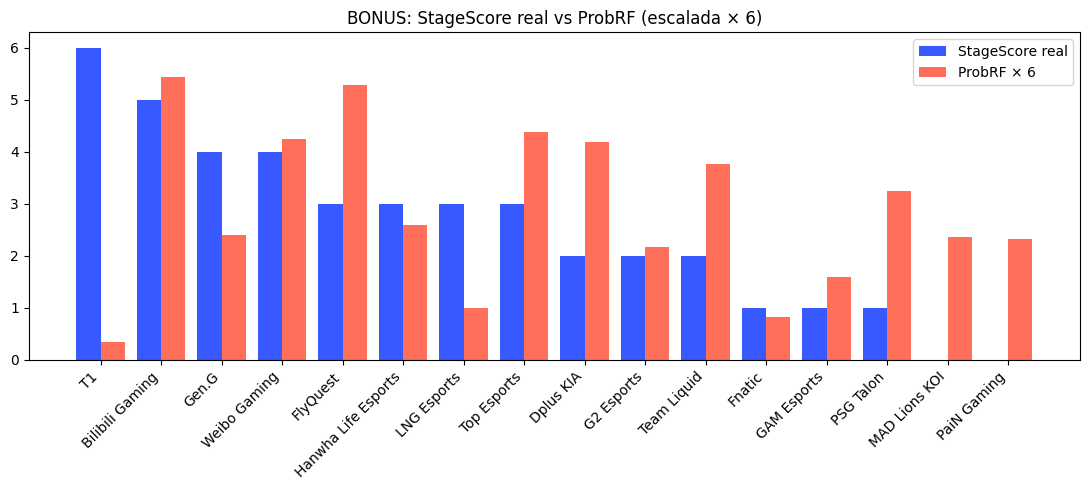

Spearman(MeanWinRate, StageScore) = 0.943
Spearman(ProbLogReg hibrido, StageScore) = 0.908


In [31]:
# Grafico: barras StageScore real vs ProbRF
order = cmp_df.sort_values('StageScore', ascending=False).index
fig, ax = plt.subplots(figsize=(11, 5))
xpos = np.arange(len(order))
ax.bar(xpos - 0.2, cmp_df.loc[order, 'StageScore'], width=0.4,
       color=PALETTE['pri'], label='StageScore real')
ax.bar(xpos + 0.2, cmp_df.loc[order, 'ProbRF']*6, width=0.4,
       color=PALETTE['sec'], label='ProbRF × 6')
ax.set_xticks(xpos)
ax.set_xticklabels(cmp_df.loc[order, 'TeamName'], rotation=45, ha='right')
ax.set_title('BONUS: StageScore real vs ProbRF (escalada × 6)')
ax.legend()
fig.tight_layout()
fig.savefig('figures/11_bonus_modelo_vs_real.png', dpi=120, bbox_inches='tight')
plt.show()

# Spearman descriptivo
rho_wr_score, _ = spearmanr(cmp_df['MeanWinRate'], cmp_df['StageScore'])
rho_pr_score, _ = spearmanr(cmp_df['ProbLogReg'], cmp_df['StageScore'])
print(f'Spearman(MeanWinRate, StageScore) = {rho_wr_score:.3f}')
print(f'Spearman(ProbLogReg hibrido, StageScore) = {rho_pr_score:.3f}')


In [32]:
errs = cmp_df[cmp_df['HitLogReg'] == 0][['TeamName','SwissRecord','AdvancedToKnockout',
                                            'PredLogReg','ProbLogReg','MeanWinRate']]
print('Errores LogReg hibrido (BONUS):')
print(errs.to_string(index=False))
print('\n> Posibles causas: bracket/draw, drafts, formato Swiss con bajo numero '
      'de partidas, adaptacion en series Bo3/Bo5, y que las metricas son agregadas.')


Errores LogReg hibrido (BONUS):
   TeamName SwissRecord  AdvancedToKnockout  PredLogReg  ProbLogReg  MeanWinRate
Top Esports         3-1                   1           0       0.187          0.5
Team Liquid         2-3                   0           1       0.822          0.5

> Posibles causas: bracket/draw, drafts, formato Swiss con bajo numero de partidas, adaptacion en series Bo3/Bo5, y que las metricas son agregadas.


## Interpretation of the bracket check

The hybrid logistic model classified 14 of the 16 team outcomes correctly under leave-one-team-out fitting. The corresponding baseline logistic model classified 12 of 16 correctly. The sample contains one aggregate observation per player, and preprocessing used the full sample. These counts describe retrospective agreement. A prospective test would need features computed only from matches that had happened by the prediction date, with transforms fitted on training data.